# SmartHire: Job Family Clustering,

In [12]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # make src/ importable

%load_ext autoreload
%autoreload 2

import pandas as pd
from src import config

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from src.features.text_features import build_tfidf

resumes = pd.read_csv(config.RESUMES_CLEAN)
X, y = resumes["Resume"], resumes["Category"]
print(len(X), "resumes |", y.nunique(), "classes")

166 resumes | 25 classes


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from src.models.recommender import JobRecommender
from src.models.clustering import reduce_dimensions, evaluate_k, describe_clusters

jobs = pd.read_csv(config.JOBS_CLEAN)
rec = JobRecommender().fit(jobs)                      # reuse the same TF-IDF space
lsa, X_reduced = reduce_dimensions(rec.job_matrix)
print("Reduced:", rec.job_matrix.shape, "->", X_reduced.shape)

Reduced: (21344, 50000) -> (21344, 100)


## Choosing k

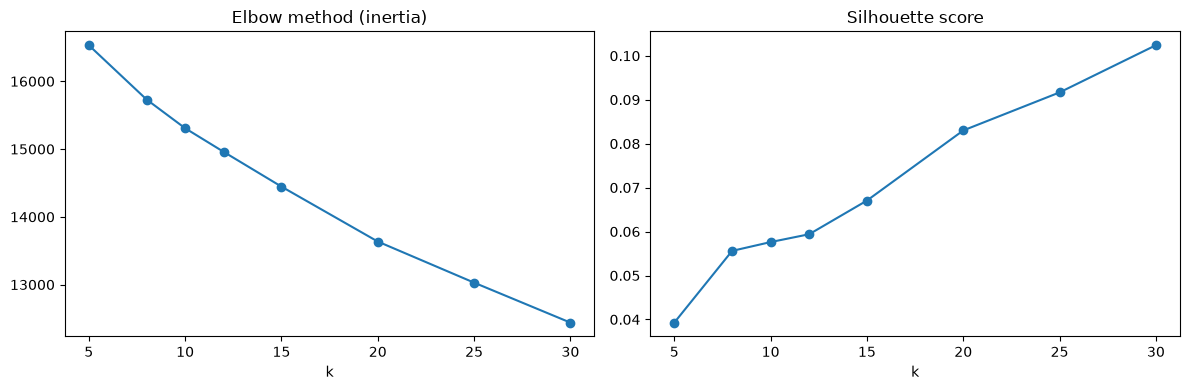

,k,inertia,silhouette
0,5,16532.701,0.039
1,8,15731.269,0.056
2,10,15307.634,0.058
3,12,14959.026,0.059
4,15,14446.072,0.067
5,20,13635.471,0.083
6,25,13029.048,0.092
7,30,12439.055,0.102


In [15]:
k_eval = evaluate_k(X_reduced, [5, 8, 10, 12, 15, 20, 25, 30])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k_eval.plot(x="k", y="inertia", marker="o", ax=axes[0], legend=False, title="Elbow method (inertia)")
k_eval.plot(x="k", y="silhouette", marker="o", ax=axes[1], legend=False, title="Silhouette score")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "04_choose_k.png", dpi=150)
plt.show()
k_eval.round(3)

## Job Families (k = 15)

In [16]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=15, n_init=10, random_state=config.RANDOM_STATE).fit(X_reduced)
clusters = describe_clusters(km, lsa, rec.vectorizer, jobs)

pd.set_option("display.max_colwidth", 80)
clusters

,cluster,size,top_terms,top_skills,example_titles
0,0,1386,"manager, assistant, assistant manager, management, project, project manager,...","sales, accounting, marketing, communication, compliance",project manager | marketing manager | business development manager
1,1,2241,"software, design, development, technical, test, testing, data, team","communication, java, sql, agile, linux",senior software engineer | software engineer | qa engineer
2,2,1088,"developer, sap, android, consultant, ios, mobile, development, android devel...","sap, java, communication, sql, html",android developer | ios developer | mobile application developer
3,3,711,"java, ee, developer, java developer, java ee, spring, hibernate, developer java","java, hibernate, sql, oracle, javascript",java developer | senior java developer | java developers
4,4,1217,"developer, designer, web, php, html, css, javascript, ui","html, css, javascript, php, jquery",php developer | web designer | graphic designer
5,5,1301,"engineer, design, design engineer, mechanical, electrical, software engineer...","communication, maintenance, linux, autocad, java",software engineer | senior software engineer | design engineer
6,6,2180,"sales, manager, business, sales manager, marketing, business development, ma...","sales, marketing, communication, accounting, negotiation",business development manager | sales manager | business development executive
7,7,730,"professor, rs, pay, ph, date, advertisement, assistant professor, associate","php, leadership, recruitment, oracle, statistics",entrepreneurship - assistant professor | assistant professor - intellectual ...
8,8,950,"administrator, server, support, linux, network, administration, windows, kno...","linux, sql, communication, oracle, maintenance",system administrator | network engineer | oracle dba
9,9,807,"content, media, marketing, social, social media, writer, content writer, dig...","marketing, seo, communication, digital marketing, sales",content writer | seo executive | digital marketing manager


In [17]:
CLUSTER_NAMES = {
    0: "Project Managers",
    1: "Software Engineers",
    2: "Android Developers",
    3: "Java Developers",
    4: "Web Designers",
    5: "Design engineers",
    6: "Sales managers",
    7: "University Faculty (ads)",
    8: "System administrator",
    9: "Content writers",
    10: "Product managers",
    11: "UI Developers",
    12: "C# .NET Developer",
    13: "IT recruiter",
    14: "Sales executive",
}
clusters["name"] = clusters["cluster"].map(CLUSTER_NAMES)
clusters[["cluster", "name", "size"]]

,cluster,name,size
0,0,Project Managers,1386
1,1,Software Engineers,2241
2,2,Android Developers,1088
3,3,Java Developers,711
4,4,Web Designers,1217
5,5,Design engineers,1301
6,6,Sales managers,2180
7,7,University Faculty (ads),730
8,8,System administrator,950
9,9,Content writers,807


## Visualization

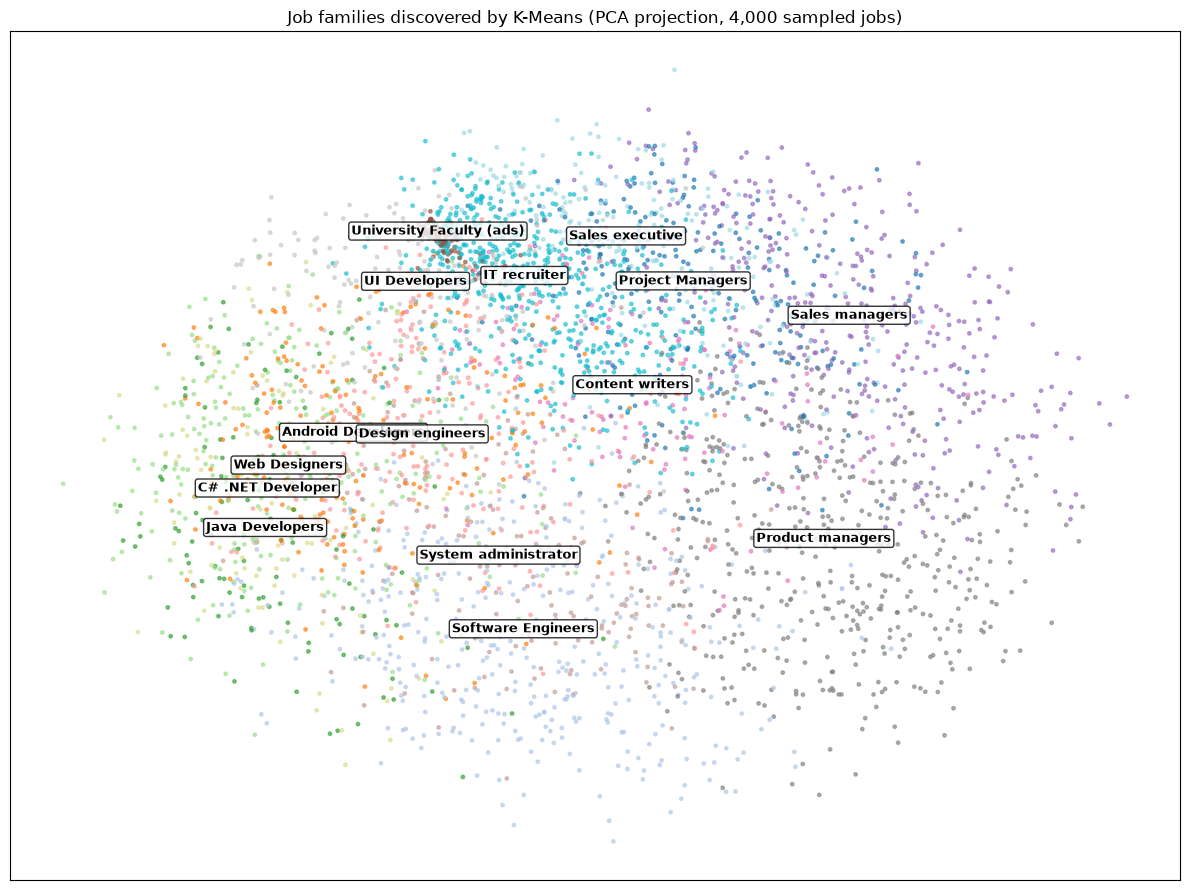

In [18]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(config.RANDOM_STATE)
sample = rng.choice(len(X_reduced), 4000, replace=False)   # 4,000 jobs keeps the plot readable
coords = PCA(n_components=2, random_state=config.RANDOM_STATE).fit_transform(X_reduced[sample])
labels = km.labels_[sample]

fig, ax = plt.subplots(figsize=(12, 9))
ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab20", s=6, alpha=0.6)
for c, name in CLUSTER_NAMES.items():
    x, y = np.median(coords[labels == c], axis=0)
    ax.annotate(name, (x, y), fontsize=9, weight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
ax.set_title("Job families discovered by K-Means (PCA projection, 4,000 sampled jobs)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "04_job_clusters_pca.png", dpi=150)
plt.show()

## Conclusions

1. Finding K choice, which is better, elbow methon shows 14446.072 for 15 k and sillutes shows 0.067. 
2. Finding our which is best among these 2, By the k = 15 value,  silhoute seem better because of its numbers. Explaining even though it has a small number, its shows overlaping.
3. Limitation: K-Means groups by word patterns, not meaning, so if many posts share a template, they form their own cluster (overlaping)